> **This notebook needs the pinned fork, and no account.** It writes a local Icechunk
> repository in a temporary directory. SpatialData on Icechunk depends on
> [pull request #1107](https://github.com/scverse/spatialdata/pull/1107) plus five commits, and
> released `spatialdata` 0.8.0 lacks them. Fetch the fork, then run with the absolute path:
>
> ```shell
> pixi run -e spatial sdpr
> PYTHONPATH=<this repository>/vendor/spatialdata-1107/src pixi run -e spatial spatialdata-run
> ```
>
> `docs/fork-pin.md` explains why pixi cannot pin the fork. The outputs below ship executed.

# SpatialData on Icechunk

The rest of this repository puts AnnData matrices on Icechunk. This notebook asks a different
question about the same storage layer. SpatialData is already Zarr and already OME-NGFF, and it
carries a rich coordinate transformation model. **This notebook tests what Icechunk adds to
SpatialData.**

Icechunk can add two things:

1. **Transactional versioning**: snapshots, branches, and a failed write that records nothing.
2. **Virtual chunk references**: Icechunk presents a dataset over files that nobody can write to.
   It does not copy the files.

[`../icechunk-SpatialData/`](../icechunk-SpatialData) holds the findings and the notes for
upstream. This notebook is the demonstration.

> **This notebook runs against [PR #1107](https://github.com/scverse/spatialdata/pull/1107) with the
> five commits that `icechunk-SpatialData/upstream/` documents.** The released 0.8.0 cannot write to a
> store. `pixi run -e spatial sdpr` produces the checkout. The next cell prints the location that
> Python loaded SpatialData from:
>
> ```shell
> pixi run -e spatial sdpr        # clones into vendor/spatialdata-1107 at the pinned commit
> PYTHONPATH=$PWD/vendor/spatialdata-1107/src pixi run -e spatial spatialdata-run
> ```

The result: **versioning works, and SpatialData already plans it. Virtual references work, and
SpatialData has no plan for them.** Geometry needs one attribute upstream. The five commits add
that attribute.

In [1]:
import pathlib
import sys

PROJECT_ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
                    if (p / "pixi.toml").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import os
import shutil
import tempfile
import warnings

warnings.simplefilter("ignore")

import icechunk
import matplotlib.pyplot as plt
import numpy as np
import spatialdata
import zarr
from spatialdata.datasets import blobs
from spatialdata.transformations import get_transformation

import icechunk_spatialdata as isd

WORKDIR = tempfile.mkdtemp(prefix="spatialdata-icechunk-")
# Caps the connections one compute opens. The repositories below add retries.
isd.bounded_reads()
print(f"spatialdata {spatialdata.__version__}   icechunk {icechunk.__version__}   "
      f"zarr {zarr.__version__}")
# `pixi run -e spatial sdpr` fetches the branch this notebook needs: PR #1107 plus the five
# commits that icechunk-SpatialData/upstream/ documents. It reports 0.8.0, so print the path.
_where = pathlib.Path(spatialdata.__file__).parent
print("loaded from an installed release" if "site-packages" in str(_where)
      else "loaded from a source checkout; see the note above")
if not isd.parquet_in_store_available():
    raise RuntimeError("this spatialdata has no `parquet_fs_fallback`; see the note above")

spatialdata 0.8.0   icechunk 2.3.0a1   zarr 3.4.1
loaded from a source checkout; see the note above


## The dataset

The notebook uses `spatialdata.datasets.blobs()`. The dataset is synthetic. It is small, so every
claim below runs in seconds. It has one element of each type. The differences below are *per element
type*, not per dataset.

In [2]:
sdata = blobs()
for kind in ("images", "labels", "points", "shapes", "tables"):
    print(f"  {kind:<8} {sorted(getattr(sdata, kind))}")
print()
print("images and labels are Zarr arrays; tables are AnnData-in-Zarr;")
print("points and shapes are Parquet *beside* the Zarr hierarchy, which is the whole story.")

  images   ['blobs_image', 'blobs_multiscale_image']
  labels   ['blobs_labels', 'blobs_multiscale_labels']
  points   ['blobs_points']
  shapes   ['blobs_circles', 'blobs_multipolygons', 'blobs_polygons']
  tables   ['table']

images and labels are Zarr arrays; tables are AnnData-in-Zarr;
points and shapes are Parquet *beside* the Zarr hierarchy, which is the whole story.


## 1. `SpatialData.write()`, to a store

With PR #1107 and the five commits, `SpatialData.write()` takes the Icechunk store itself. Rasters
and tables are Zarr already. Shapes and points are Parquet files. `isd.parquet_in_store()` makes
each file a `uint8` Zarr array at the path that SpatialData requests. The write goes through
SpatialData's own writers.

In [3]:
repo = icechunk.Repository.create(
    icechunk.local_filesystem_storage(os.path.join(WORKDIR, "repo"))
)

with isd.transaction(repo, "main", "blobs") as tx, isd.parquet_in_store():
    sdata.write(tx.session.store)
print(f"committed {tx.snapshot}")

  2026-10-09T22:23:07.518878Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:330

  2026-10-09T22:23:07.529722Z  WARN icechunk_storage::readback: conditional PUT is enabled but `unsafe_use_metadata` is disabled — lost-response recovery for conditional writes requires user metadata to stamp write-ids; without it, transient PUT failures may surface as spurious conflicts even when the write actually landed. See icechunk_storage::Settings::unsafe_use_metadata.
    at icechunk-storage/src/readback.rs:31



committed XQDN0SDR2EM4R7GRW6A0


In [4]:
root = zarr.open_group(repo.readonly_session("main").store, mode="r")
print("inside the Icechunk repository:")
for path, node in sorted(root.members(max_depth=3)):
    kind = "group" if isinstance(node, zarr.Group) else f"{node.shape} {node.dtype}"
    print(f"  {path:<46} {kind}")

inside the Icechunk repository:
  images                                         group
  images/blobs_image                             group
  images/blobs_image/s0                          (3, 512, 512) float64
  images/blobs_multiscale_image                  group
  images/blobs_multiscale_image/s0               (3, 512, 512) float64
  images/blobs_multiscale_image/s1               (3, 256, 256) float64
  images/blobs_multiscale_image/s2               (3, 128, 128) float64
  labels                                         group
  labels/blobs_labels                            group
  labels/blobs_labels/s0                         (512, 512) int16
  labels/blobs_multiscale_labels                 group
  labels/blobs_multiscale_labels/s0              (512, 512) int16
  labels/blobs_multiscale_labels/s1              (256, 256) int16
  labels/blobs_multiscale_labels/s2              (128, 128) int16
  points                                         group
  points/blobs_points              

The store holds the multiscale pyramids as `s0`, `s1`, `s2`. The AnnData table and the Parquet files
are *inside* the store, not beside it.

`SpatialData.read()` takes the store too, and the coordinate transformations stay intact. The
transformations are Zarr attributes, and Icechunk versions them like any other data.

In [5]:
def finest(element):
    """An element's data, or its finest scale if it is a multiscale DataTree."""
    if getattr(element, "children", None):
        return np.asarray(next(iter(element["scale0"].ds.values())).data)
    return np.asarray(element.data)


with isd.parquet_in_store():
    back = spatialdata.read_zarr(repo.readonly_session("main").store)
print(back)
print()
for kind in ("images", "labels"):
    for name, element in getattr(sdata, kind).items():
        # Both sides go through `finest`. A multiscale element round-trips as a pyramid with
        # levels, not a single `.data`.
        got = finest(getattr(back, kind)[name])
        same = got.shape == finest(element).shape and np.allclose(got, finest(element))
        print(f"  {kind}/{name:<24} identical={same}   "
              f"transform={get_transformation(getattr(back, kind)[name])}")
print(f"  tables/table              shape={back.tables['table'].shape}")
for name, frame in sdata.shapes.items():
    same = np.array_equal(frame.geometry.to_wkb().to_numpy(),
                          back.shapes[name].geometry.to_wkb().to_numpy())
    print(f"  shapes/{name:<24} geometry identical={same}")

no parent found for <ome_zarr.reader.Label object at 0x325ed3a40>: None


no parent found for <ome_zarr.reader.Label object at 0x325fb80b0>: None


SpatialData object
├── Images
│     ├── 'blobs_image': DataArray[cyx] (3, 512, 512)
│     └── 'blobs_multiscale_image': DataTree[cyx] (3, 512, 512), (3, 256, 256), (3, 128, 128)
├── Labels
│     ├── 'blobs_labels': DataArray[yx] (512, 512)
│     └── 'blobs_multiscale_labels': DataTree[yx] (512, 512), (256, 256), (128, 128)
├── Points
│     └── 'blobs_points': DataFrame with shape: (200, 4) (2D points)
├── Shapes
│     ├── 'blobs_circles': GeoDataFrame shape: (5, 2) (2D shapes)
│     ├── 'blobs_multipolygons': GeoDataFrame shape: (2, 1) (2D shapes)
│     └── 'blobs_polygons': GeoDataFrame shape: (5, 1) (2D shapes)
└── Tables
      └── 'table': AnnData (26, 3)
with coordinate systems:
    ▸ 'global', with elements:
        blobs_image (Images), blobs_multiscale_image (Images), blobs_labels (Labels), blobs_multiscale_labels (Labels), blobs_points (Points), blobs_circles (Shapes), blobs_multipolygons (Shapes), blobs_polygons (Shapes)

  images/blobs_image              identical=True   tran

## 2. Versioning

An annotation pass becomes a snapshot, not a mutation. The earlier state stays readable.

In [6]:
second = repo.writable_session("main")
zarr.open_group(second.store, mode="a").attrs["annotated_by"] = "a later pass"
second_snapshot = second.commit("annotate")

for label, snapshot in [("first", tx.snapshot), ("second", second_snapshot)]:
    attrs = dict(zarr.open_group(
        repo.readonly_session(snapshot_id=snapshot).store, mode="r").attrs)
    print(f"  {label:<7} {snapshot}  annotated_by={attrs.get('annotated_by')!r}")

print("\nhistory:")
for entry in repo.ancestry(branch="main"):
    print(f"  {entry.id}  {entry.message}")

  first   XQDN0SDR2EM4R7GRW6A0  annotated_by=None
  second  RRVX4MFHRHWDNRV9QVH0  annotated_by='a later pass'

history:
  RRVX4MFHRHWDNRV9QVH0  annotate
  XQDN0SDR2EM4R7GRW6A0  blobs
  1CECHNKREP0F1RSTCMT0  Repository initialized


### And the part a filesystem cannot do

`SpatialData.write()` writes one element at a time and cannot roll back. If it fails partway, the
disk holds a partial dataset. The next reader has to detect it. In a transaction, a failure does
not change the branch.

In [7]:
# An empty repository makes "nothing was recorded" unambiguous.
doomed_repo = icechunk.Repository.create(
    icechunk.local_filesystem_storage(os.path.join(WORKDIR, "doomed"))
)
before = [entry.id for entry in doomed_repo.ancestry(branch="main")]

class Interrupted(Exception):
    pass

try:
    with isd.transaction(doomed_repo, "main", "doomed") as doomed, isd.parquet_in_store():
        sdata.write(doomed.session.store)         # a complete write...
        raise Interrupted("something went wrong halfway through")   # ...then a failure
except Interrupted as exc:
    print(f"raised: {exc}")

after = [entry.id for entry in doomed_repo.ancestry(branch="main")]
print(f"  snapshot recorded: {doomed.snapshot}")
print(f"  commits before: {len(before)}   after: {len(after)}   unchanged: {before == after}")
print("  the elements were written to the session and then simply never became a snapshot")

  2026-10-09T22:23:07.885742Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:330



raised: something went wrong halfway through
  snapshot recorded: None
  commits before: 1   after: 1   unchanged: True
  the elements were written to the session and then simply never became a snapshot


## 3. Geometry: how the Parquet got in

SpatialData writes shapes and points as **Parquet outside the Zarr hierarchy**. Its own source says
the file "is not recognized as part of the zarr hierarchy as it is not a valid component of a zarr
store." Icechunk refuses non-Zarr keys outright. The direct method buffers the Parquet and gives
the bytes to the store. That method cannot work.

In [8]:
from zarr.core.buffer import default_buffer_prototype
from zarr.core.sync import sync   # a notebook already has a running event loop

payload = default_buffer_prototype().buffer.from_bytes(b"PAR1...")
KEY = "shapes/x/shapes.parquet"

try:
    sync(repo.writable_session("main").store.set(KEY, payload))
    print("Icechunk accepted a non-Zarr key")
except Exception as exc:
    print(f"Icechunk refuses non-Zarr keys: {type(exc).__name__}")
    print(f"  {str(exc).splitlines()[0][:110]}")

sync(zarr.storage.LocalStore(os.path.join(WORKDIR, "plain")).set(KEY, payload))
print("a LocalStore accepts the same key, so this is Icechunk's boundary, not a bug")

Icechunk refuses non-Zarr keys: InvalidInputError
  invalid zarr key format `shapes/x/shapes.parquet`
a LocalStore accepts the same key, so this is Icechunk's boundary, not a bug


### The method that needs no format change

PR #1107 does not give the writers a *path*. It gives them an **fsspec filesystem**. The geometry
writers only call `fs.open(...)`. Zarr accepts `shapes.parquet` as an array name, at the exact path
that SpatialData requests.

So a *file* can be a 1-D `uint8` Zarr array. The fsspec namespace and the Zarr namespace are then
identical. `ZarrArrayFileSystem` is about 120 lines. `parquet_in_store()` gives it to SpatialData
through `parquet_fs_fallback`. The five commits add that one attribute.

In [9]:
from icechunk_spatialdata import ZarrArrayFileSystem

demo = zarr.create_group(store=os.path.join(WORKDIR, "fs-demo.zarr"), zarr_format=3)
fs = ZarrArrayFileSystem(demo)
blob = bytes(range(256)) * 8

with fs.open("shapes/x/shapes.parquet", "wb") as sink:
    sink.write(blob)
with fs.open("shapes/x/shapes.parquet", "rb") as src:
    assert src.read() == blob

stored = demo["shapes/x/shapes.parquet"]
print(f"the 'file' is a Zarr array: {stored.shape} {stored.dtype} at {stored.path!r}")
print(f"  attrs: {dict(stored.attrs)}")
print(f"  fs.info: {fs.info('shapes/x/shapes.parquet')}")

the 'file' is a Zarr array: (2048,) uint8 at 'shapes/x/shapes.parquet'
  attrs: {'zarr_conventions': [{'uuid': '6cdb4f72-1a6a-4ca0-a008-f4ff70bd0024', 'name': 'file:', 'description': "This array's elements are the bytes of a file; its node path is the file's path."}], 'file:name': 'shapes.parquet'}
  fs.info: {'name': 'shapes/x/shapes.parquet', 'size': 2048, 'type': 'file'}


In [10]:
print("geometry inside the Icechunk repository, in SpatialData's own format:")
for path, node in sorted(root.members(max_depth=4)):
    if path.endswith(".parquet") and not isinstance(node, zarr.Group):
        print(f"  {path:<52} {node.shape[0]:>7,} bytes")

geometry inside the Icechunk repository, in SpatialData's own format:


  points/blobs_points/points.parquet/part.0.parquet      6,858 bytes
  shapes/blobs_circles/shapes.parquet                    3,210 bytes
  shapes/blobs_multipolygons/shapes.parquet              3,339 bytes
  shapes/blobs_polygons/shapes.parquet                   3,068 bytes


## 4. A table that holds no expression data

SpatialData has no plan for this part. It needs no API at all. It needs only a coincidence between
two formats.

An `.h5ad` stores `X` as `X/data`, `X/indices`, `X/indptr`. AnnData-in-Zarr stores it as a group
with **the same three array names**. So the Zarr arrays can be byte-range references into the chunks
of the HDF5 file. `anndata.io.read_elem` reads the result as an ordinary `csr_matrix`.

The source is a real public Visium dataset: CZI's first-trimester placenta slide. The notebook reads
it anonymously over S3. The notebook copies nothing.

In [11]:
from anndata.io import read_elem
from obspec_utils.registry import ObjectStoreRegistry
from obstore.store import S3Store

import braun  # holds the census bucket constants

DATASET = "993cf43f-3b5b-424e-a67a-6ccf0a328450"   # Visium, first-trimester placenta
SOURCE = braun.census_h5ad_url(DATASET)
registry = ObjectStoreRegistry(
    {braun.PREFIX: S3Store(braun.BUCKET, region=braun.REGION, skip_signature=True)}
)

config = isd.repository_config(
    icechunk.VirtualChunkContainer(
        braun.PREFIX, icechunk.s3_store(region=braun.REGION, anonymous=True)
    )
)
virtual_repo = icechunk.Repository.create(
    icechunk.local_filesystem_storage(os.path.join(WORKDIR, "virtual")),
    config=config,
    authorize_virtual_chunk_access=icechunk.containers_credentials(
        {braun.PREFIX: icechunk.s3_anonymous_credentials()}
    ),
)

print(f"source  {SOURCE}")
print(f"references needed: {isd.reference_count(SOURCE, registry):,}")

source  s3://cellxgene-census-public-us-west-2/cell-census/2025-11-08/h5ads/993cf43f-3b5b-424e-a67a-6ccf0a328450.h5ad


  2026-10-09T22:23:08.115406Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:330



references needed: 1,540


In [12]:
session = virtual_repo.writable_session("main")
vroot = zarr.create_group(store=session.store, zarr_format=3)
isd.virtual_table(vroot, "table", session, SOURCE, registry)
snapshot = session.commit("a table whose X is somebody else's file")

table = read_elem(
    zarr.open_group(virtual_repo.readonly_session("main").store, mode="r")["table"]
)
stored = braun.directory_size(os.path.join(WORKDIR, "virtual"))
print(f"read back with unmodified anndata: {type(table).__name__} {table.shape}")
print(f"  X is a {type(table.X).__name__} with {table.X.nnz:,} stored values")
print(f"  the whole repository is {stored / 1e6:.2f} MB")
print(f"  per-spot totals, first five: {np.asarray(table.X[:5].sum(axis=1)).ravel()}")

read back with unmodified anndata: AnnData (4992, 32397)
  X is a csr_matrix with 8,990,335 stored values
  the whole repository is 0.07 MB
  per-spot totals, first five: [ 418. 9355.  512.  598.  217.]


The notebook reads those five totals from CZI's bucket, one chunk at a time. The repository holds
only the locations of the bytes.

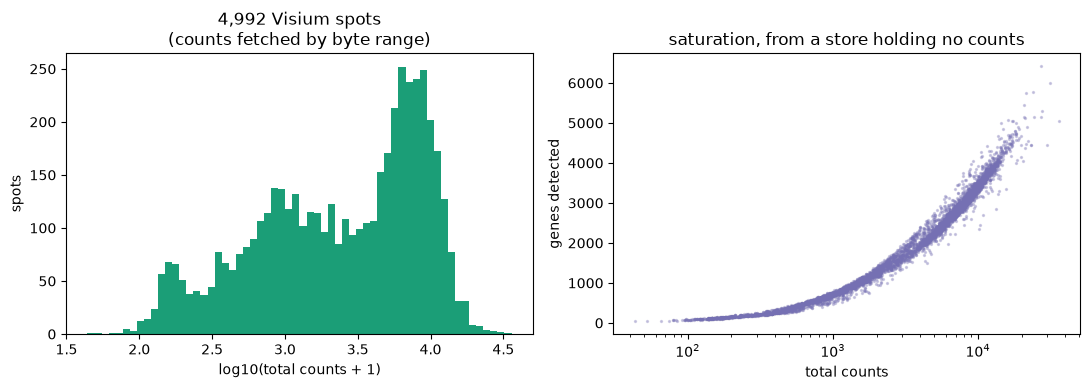

In [13]:
counts = np.asarray(table.X.sum(axis=1)).ravel()
detected = np.asarray((table.X > 0).sum(axis=1)).ravel()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log10(counts + 1), bins=60, color="#1b9e77")
axes[0].set_xlabel("log10(total counts + 1)"); axes[0].set_ylabel("spots")
axes[0].set_title(f"{table.n_obs:,} Visium spots\n(counts fetched by byte range)")
axes[1].scatter(counts, detected, s=2, alpha=0.3, color="#7570b3")
axes[1].set_xscale("log"); axes[1].set_xlabel("total counts")
axes[1].set_ylabel("genes detected")
axes[1].set_title("saturation, from a store holding no counts")
fig.tight_layout()
plt.show()

## 5. The same method on a 670 MB Parquet

A Xenium bundle is mostly not h5ad. Its geometry and its transcripts are Parquet.
`transcripts.parquet` alone is **670 MB**. That is forty times the size of all other files in the
bundle, except the images.

The notebook can reference those files too. **A `uint8` array has no codec, so a chunk is exactly a
byte range.** An array with a codec needs the source's own encoding to match. That requirement
blocks the images, below. An opaque byte array needs no match at all. So the map from file offsets
to chunk indices is always exact, for any format.

The notebook has to copy one chunk of the file. Zarr chunks have a fixed size. If the file length
is not a multiple of that size, the final chunk needs padding. A byte range cannot pad. Everything
before that chunk is a reference.

In [14]:
TRANSCRIPTS = ("https://s3-us-west-2.amazonaws.com/10x.files/samples/xenium/1.0.1/"
               "Xenium_FFPE_Human_Breast_Cancer_Rep1/"
               "Xenium_FFPE_Human_Breast_Cancer_Rep1_transcripts.parquet")
TENX_HOST = "https://s3-us-west-2.amazonaws.com/10x.files/"

import requests
from icechunk_spatialdata import ZarrArrayFileSystem, reference_file

transcripts_size = int(requests.head(TRANSCRIPTS).headers["content-length"])

config = isd.repository_config(
    icechunk.VirtualChunkContainer(TENX_HOST, icechunk.http_store())
)
parquet_repo = icechunk.Repository.create(
    icechunk.local_filesystem_storage(os.path.join(WORKDIR, "parquet")),
    config=config,
    authorize_virtual_chunk_access={TENX_HOST: icechunk.credentials.HttpAccess},
)

session = parquet_repo.writable_session("main")
proot = zarr.create_group(store=session.store, zarr_format=3)
references = reference_file(
    proot, "points/transcripts/points.parquet", TRANSCRIPTS, transcripts_size, session
)
session.commit("670 MB of transcripts, referenced")

stored = braun.directory_size(os.path.join(WORKDIR, "parquet"))
print(f"source file      {transcripts_size / 1e6:>8.1f} MB")
print(f"references       {references:>8,} chunks")
print(f"repository       {stored / 1e6:>8.1f} MB  "
      f"({stored / transcripts_size:.2%} of the file, the copied tail)")

  2026-10-09T22:25:50.455184Z  WARN icechunk_arrow_object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk-arrow-object-store/src/lib.rs:330



source file         669.8 MB
references            159 chunks
repository            4.2 MB  (0.63% of the file, the copied tail)


### What a read actually costs

Many chunks, not one, let the reader fetch only the slices it needs. A read of the footer does not
read the body.

In [15]:
import pyarrow.parquet as pq

read_only = zarr.open_group(parquet_repo.readonly_session("main").store, mode="r")
filesystem = ZarrArrayFileSystem(read_only)

handle = filesystem.open("points/transcripts/points.parquet", "rb")
parquet = pq.ParquetFile(handle)
groups = [parquet.metadata.row_group(i).num_rows
          for i in range(parquet.metadata.num_row_groups)]
after_metadata = handle.raw.bytes_read
print(f"metadata: {parquet.metadata.num_row_groups} row groups, "
      f"{sum(groups):,} transcripts")
print(f"  bytes read: {after_metadata / 1e6:.2f} MB of "
      f"{transcripts_size / 1e6:.0f} MB ({after_metadata / transcripts_size:.2%})")

# The footer disagrees with its own row groups. The aside below explains.
print(f"  the footer's own num_rows: {parquet.metadata.num_rows:,}")

batch = parquet.read_row_group(0)
after_group = handle.raw.bytes_read
print()
print(f"one row group: {batch.num_rows:,} transcripts, columns {batch.column_names}")
print(f"  cumulative bytes read: {after_group / 1e6:.1f} MB "
      f"({after_group / transcripts_size:.1%} of the file)")

metadata: 43 row groups, 42,638,083 transcripts
  bytes read: 0.07 MB of 670 MB (0.01%)
  the footer's own num_rows: 1,000,000



one row group: 1,000,000 transcripts, columns ['transcript_id', 'cell_id', 'overlaps_nucleus', 'feature_name', 'x_location', 'y_location', 'z_location', 'qv']
  cumulative bytes read: 16.3 MB (2.4% of the file)


That file's footer declares `num_rows = 1,000,000`. Its 43 row groups sum to 42,638,083.
`fastparquet-python 1.0.0` wrote the file. `cell_boundaries.parquet` has the same discrepancy. An
independent ranged read of the published file confirmed it. So the fault is in the file, not in
this notebook. Code that trusts `metadata.num_rows` on these files is wrong by a factor of forty.

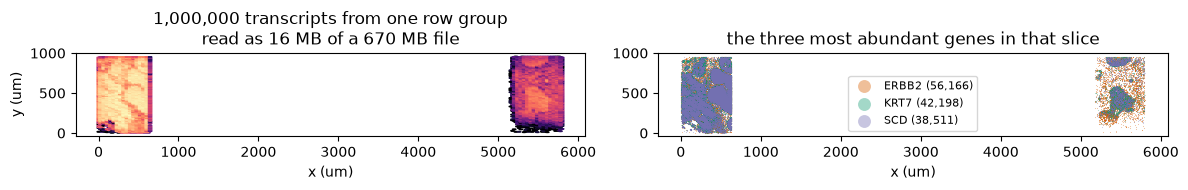

median quality score in this slice: 40.0


In [16]:
positions = np.column_stack([batch.column("x_location").to_numpy(),
                            batch.column("y_location").to_numpy()])
# fastparquet wrote feature_name as plain BYTE_ARRAY with no UTF8 logical type.
# So pyarrow returns bytes, not str.
genes = [g.decode() if isinstance(g, bytes) else g
         for g in batch.column("feature_name").to_pylist()]
quality = batch.column("qv").to_numpy()
top = [g for g, _ in __import__("collections").Counter(genes).most_common(3)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hexbin(positions[:, 0], positions[:, 1], gridsize=140, cmap="magma", bins="log")
axes[0].set_title(f"{batch.num_rows:,} transcripts from one row group\n"
                  f"read as {after_group / 1e6:.0f} MB of a "
                  f"{transcripts_size / 1e6:.0f} MB file")
axes[0].set_xlabel("x (um)"); axes[0].set_ylabel("y (um)")

palette = ["#d95f02", "#1b9e77", "#7570b3"]
for colour, gene in zip(palette, top):
    keep = np.array([g == gene for g in genes])
    axes[1].scatter(positions[keep, 0], positions[keep, 1], s=0.6, alpha=0.4,
                    color=colour, label=f"{gene} ({keep.sum():,})", linewidths=0)
axes[1].set_title("the three most abundant genes in that slice")
axes[1].set_xlabel("x (um)")
axes[1].legend(markerscale=12, fontsize=8)
for ax in axes:
    ax.set_aspect("equal")
fig.tight_layout()
plt.show()

print(f"median quality score in this slice: {np.median(quality):.1f}")

### One caveat that the picture shows

A row group is a slice of the **file**, not of the tissue. Those transcripts occupy two narrow
vertical bands, not a representative patch. Parquet row groups follow write order. This file's
write order is only loosely spatial.

This matters for ranged reads. One row group is cheap to fetch, but it is not a spatial subset. To
get a region of tissue, a reader must read and filter the whole column. Or it needs an index that
the format does not carry. The references inherit the source's layout. They do not choose it.

### And the images, as files rather than arrays

The same method works on the OME-TIFFs. Its result differs from the result of a JPEG 2000 codec.

The file reference works exactly as it did for Parquet. The reference uses no codec, so a chunk is
a byte range. `tifffile` reads the file through the same lazy handle. It decodes JPEG 2000 itself
through `imagecodecs`. The result is **a file inside the store**, not an image element. The pixels
are not a Zarr array, so no Zarr-native tool can see them. That distinction is the codec gap.

In [17]:
MORPHOLOGY = ("https://s3-us-west-2.amazonaws.com/10x.files/samples/xenium/1.0.1/"
              "Xenium_FFPE_Human_Breast_Cancer_Rep1/"
              "Xenium_FFPE_Human_Breast_Cancer_Rep1_morphology_mip.ome.tif")
import tifffile

morphology_size = int(requests.head(MORPHOLOGY).headers["content-length"])
session = parquet_repo.writable_session("main")
mroot = zarr.open_group(session.store, mode="a")
image_references = reference_file(
    mroot, "images/morphology.ome.tif", MORPHOLOGY, morphology_size, session, chunk=1 << 20
)
session.commit("an OME-TIFF, referenced as an opaque file")

image_store = zarr.open_group(parquet_repo.readonly_session("main").store, mode="r")
handle = ZarrArrayFileSystem(image_store).open("images/morphology.ome.tif", "rb")
tif = tifffile.TiffFile(handle)
series = tif.series[0]
structure_cost = handle.raw.bytes_read

print(f"source file    {morphology_size / 1e6:>8.1f} MB, JPEG 2000 tiles")
print(f"references     {image_references:>8,} chunks")
print(f"pyramid        {len(series.levels)} levels, {series.shape} {series.dtype}")
print(f"structure read {structure_cost / 1e6:>8.2f} MB "
      f"({structure_cost / morphology_size:.2%} of the file)")

source file       627.8 MB, JPEG 2000 tiles
references          598 chunks
pyramid        8 levels, (25778, 35416) uint16
structure read     0.65 MB (0.10% of the file)


pyramid level 5: (805, 1106) uint16
  bytes for it: 0.92 MB (0.15% of the file)


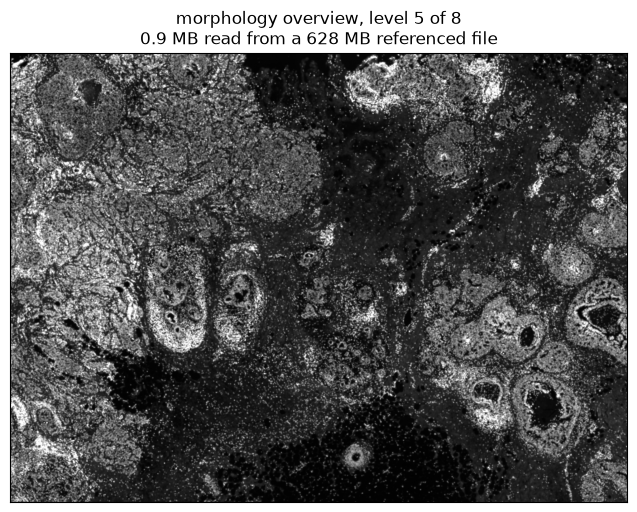

In [18]:
before = handle.raw.bytes_read
overview = series.levels[5].asarray()
overview_cost = handle.raw.bytes_read - before
print(f"pyramid level 5: {overview.shape} {overview.dtype}")
print(f"  bytes for it: {overview_cost / 1e6:.2f} MB "
      f"({overview_cost / morphology_size:.2%} of the file)")

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.imshow(overview, cmap="gray", vmax=np.percentile(overview, 99.5))
ax.set_title(f"morphology overview, level 5 of {len(series.levels)}\n"
             f"{overview_cost / 1e6:.1f} MB read from a "
             f"{morphology_size / 1e6:.0f} MB referenced file")
ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()
plt.show()

A downsampled overview costs a fraction of a percent of the file. An interactive viewer needs
exactly that. So a viewer can browse a pyramid inside an opaque file reference.

One limit applies. A read of a *full-resolution tile* needs `tifffile`'s own Zarr view. zarr 3
cannot open a `ZarrTiffStore`, because it is a v2-style mapping, not a `Store`. `asarray()` decodes
the entire level instead. For level 0, it fetched 450 MB. So this method gives no cheap random
access at full resolution.

So a repository can hold a whole Xenium bundle and store almost none of its bytes. The table's `X`
is references into an h5ad. The geometry and transcripts are references into the published
Parquet. The images are file references. The images as *arrays* are still missing. That is the
codec gap, below.

## 6. The remaining blocker: nothing else opens the store

Everything above works with no change to SpatialData or Icechunk. **No other tool can open the
store.**

In [19]:
group = zarr.open_group(repo.readonly_session("main").store, mode="r")
try:
    spatialdata.read_zarr(group)
    print("read_zarr accepted the store")
except Exception as exc:
    print(f"spatialdata.read_zarr(group) -> {type(exc).__name__}")
    print(f"  {str(exc).splitlines()[0][:130]}")
print()
print("On the current release this is a dead zarr-v2 reference inside _resolve_zarr_store.")
print("On PR #1107 it gets as far as the raster reader and then fails in ome-zarr-py, whose")
print("ZarrLocation type-checks its input. Either way: napari and squidpy cannot open this.")

no parent found for <ome_zarr.reader.Label object at 0x39c1de450>: None


no parent found for <ome_zarr.reader.Label object at 0x39c26d220>: None


spatialdata.read_zarr(group) -> ValueError
  Cannot derive a filesystem for store of type IcechunkStore

On the current release this is a dead zarr-v2 reference inside _resolve_zarr_store.
On PR #1107 it gets as far as the raster reader and then fails in ome-zarr-py, whose
ZarrLocation type-checks its input. Either way: napari and squidpy cannot open this.


A byte-range reference cannot re-encode bytes. That limit is narrow, as the next cell shows:

In [20]:
library = "spaceranger110_count_36173_Pla_Camb9518737_GRCh38-3_0_0_premrna"
channel_last, description = isd.images_in_h5ad_are_channel_last(
    SOURCE, registry, f"uns/spatial/{library}/images"
)
print(f"images in that same h5ad: channel_last={channel_last}")
print(f"  {description}")
print()
print("This was long recorded here as a wall: AnnData writes those images (y, x, c), an element")
print("must be (c, y, x), and a byte range cannot transpose. The premise holds and the conclusion")
print("did not. The bytes never needed transposing. Zarr v3 has a transpose codec in its core")
print("spec, so the element is (c, y, x) while the stored chunks stay channel-last. Measured at")
print("384 references on this image, reading back identical to the stored image transposed.")
print()
print("The Xenium morphology images are JPEG 2000, which Zarr v3 had no codec for when this was")
print("written. The TIFF parser this repository reads images through supplies one, so those")
print("images become references too. See ../icechunk-SpatialData/ and 'the codec, found'.")

images in that same h5ad: channel_last=True
  fullres is (2286, 2325, 4), channel-last; hires is (1967, 2000, 3), channel-last. Image2DModel requires ('c', 'y', 'x'). A transpose codec supplies that order and does not change the stored bytes

This was long recorded here as a wall: AnnData writes those images (y, x, c), an element
must be (c, y, x), and a byte range cannot transpose. The premise holds and the conclusion
did not. The bytes never needed transposing. Zarr v3 has a transpose codec in its core
spec, so the element is (c, y, x) while the stored chunks stay channel-last. Measured at
384 references on this image, reading back identical to the stored image transposed.

The Xenium morphology images are JPEG 2000, which Zarr v3 had no codec for when this was
written. The TIFF parser this repository reads images through supplies one, so those
images become references too. See ../icechunk-SpatialData/ and 'the codec, found'.


## What this shows

**Versioning works, and SpatialData already plans it.** Rasters, tables, pyramids and coordinate
transformations all commit and read back byte-identical. A failed write does not change the branch.
The hackathon report proposes an Icechunk integration in more detail than this prototype. That
report includes the exact write-lifecycle gap that this notebook found. So this result confirms
the report and is not new.

**Geometry is not a blocker.** It needs no Icechunk change and no SpatialData format change.
Geometry I/O already goes through an fsspec filesystem. A file can be a `uint8` Zarr array at the
identical path. Support for non-Zarr keys in Icechunk would work too, but it is the worse choice.
File bytes as chunks inherit compression, per-chunk conflict detection and virtual references. An
opaque blob gets none of these.

**Virtual references are the unclaimed contribution.** A table's `X` is byte ranges into a
published h5ad. Unmodified `anndata` reads it. The repository is three orders of magnitude smaller
than the data. That is this repository's thesis, applied to a different data model. No package in
the SpatialData ecosystem does it. Its "lazy file linking" prototype soft-links whole files and
defers to the source format's own reader. That is a different mechanism at a different granularity.

**Interop needs the five commits.** With them, `SpatialData.write` and `SpatialData.read` take the
store. Geometry goes through `parquet_fs_fallback`. Without it, no unmodified tool opens this store.

**A byte range cannot re-encode, and that is its only limit.** An array keeps the source's dtype and
compression. It *can* present them differently, because a Zarr codec is part of the read pipeline.
So a transpose costs nothing, and channel-last sources become `(c, y, x)` elements. That is a
property of references, not of Icechunk or SpatialData.

In [21]:
shutil.rmtree(WORKDIR, ignore_errors=True)
print("cleaned up")

cleaned up
